In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from belfast.target_definition import Target
from belfast.target_utils import query_data
import belfast.mcmc_utils as mcmc
import emcee
import numpy as np
from scipy.stats import norm
import os
from belfast.isochrone_utils import load_regularized_Mini_interpolator

from belfast.plot_utils import plot_cmd_isochrones, plot_evolution_L_R_tracks
from belfast.paths import DATA_DIR

%load_ext autoreload
%autoreload 2

In [2]:
interp_func, interp_u, interp_u_to_outputs, interp_u_bounds, interp_variable_list, interp_output_list, data, = load_regularized_Mini_interpolator(
    DATA_DIR / 'isochrones' / 'regular_PARSECv2_Mini_grids' / 'regularized_Mini_grid_1e6_2001e6yr_step10e6_linear_isochrones_MS_with_inc.npz',
    force_float64=False
)

Loaded regularized Mini grid.
grid_type: with_inc
interp_variable_list: ['Mini', 'logAge', 'MH', 'omega_ini', 'Inclination']
interp_output_list: ['Mass', 'omega', 'Req', 'Rpol', 'G', 'G_BP', 'G_RP', 'B_T', 'V_T', 'J', 'H', 'Ks']
grid_outputs shape: (1392, 201, 13, 7, 11, 12)
grid_bounds shape: (201, 13, 7, 11, 2)
grid_outputs dtype: float32
grid_bounds dtype: float32
save_float32: True
read_all_at_once: True
total grid memory: 12822.22 MB (12.52 GB)


In [3]:
interp_func_pars, interp_u_pars, interp_u_to_outputs_pars, interp_u_bounds_pars, interp_variable_list_pars, interp_output_list_pars, data_pars, = load_regularized_Mini_interpolator(
    DATA_DIR / 'isochrones' / 'regular_PARSECv2_Mini_grids' / 'regularized_Mini_grid_1e6_2001e6yr_step10e6_linear_isochrones_MS_without_inc.npz',
    force_float64=False
)

Loaded regularized Mini grid.
grid_type: without_inc
interp_variable_list: ['Mini', 'logAge', 'MH', 'omega_ini']
interp_output_list: ['Mass', 'omega', 'logL', 'Req', 'Rpol']
grid_outputs shape: (1392, 201, 13, 7, 5)
grid_bounds shape: (201, 13, 7, 2)
grid_outputs dtype: float32
grid_bounds dtype: float32
save_float32: True
read_all_at_once: True
total grid memory: 485.78 MB (0.47 GB)


In [ ]:
interp_u([1.9, np.log10(1200)+6, 0.09, 0.000001, 0.2])

In [ ]:
fig, ax = plot_cmd_isochrones(
    interp_func,
    Mini_grid=np.arange(1.5, 7.0 + 0.005, 0.005),
    ages_Myr=(600, 700, 800),
    MH=0.01,
    omega_ini_list=(0.0, 0.8),
    inclination_list=(0.0, 0.524, 1.047, 1.57),
    # color="G_BP-G_RP",
    # mag="G",
    color='B_T-V_T',
    mag='V_T',
    # color="J-Ks",
    # mag="H",
    rot_alpha_range=(0.1, 1.0),
    nonrot_alpha=0.7,
    mass_marks=(1.5, 2.0, 2.5, 3.0),
    mass_marker_cycle=("s", "^", "v", "x", "o"),
    mass_text_iso_index=0,
    mass_text_dx=-0.03,
    mass_text_dy=0.0,
)

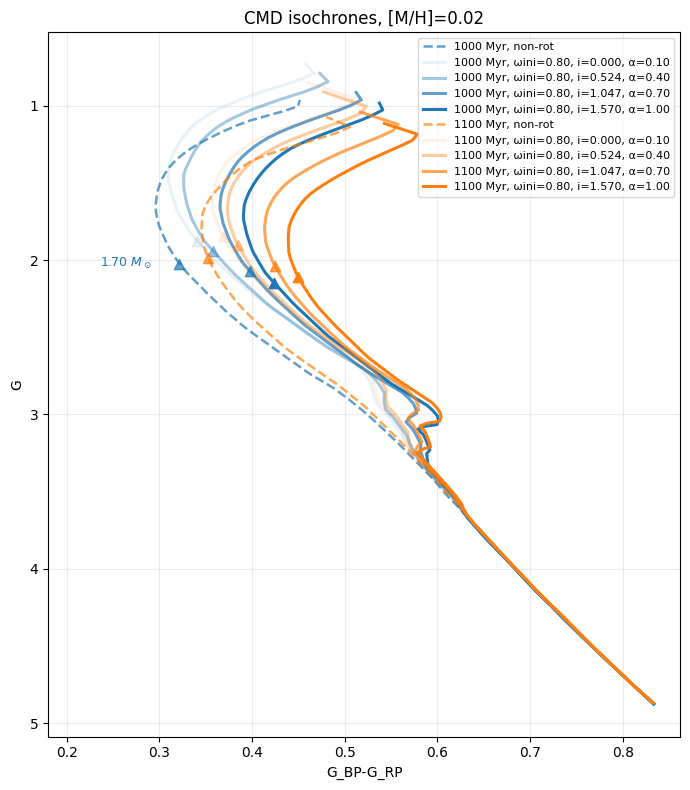

In [4]:
fig, ax = plot_cmd_isochrones(
    interp_func,
    Mini_grid=np.arange(1.0, 3.0 + 0.005, 0.005),
    ages_Myr=(1000, 1100),
    MH=0.02,
    omega_ini_list=(0.0, 0.8),
    inclination_list=(0.0, 0.524, 1.047, 1.57),
    color="G_BP-G_RP",
    mag="G",
    # color='B_T-V_T',
    # mag='V_T',
    # color="J-Ks",
    # mag="H",
    rot_alpha_range=(0.1, 1.0),
    nonrot_alpha=0.7,
    mass_marks=(1.7, ),
    mass_marker_cycle=("^", "s", "v", "x", "o"),
    mass_text_iso_index=0,
    mass_text_dx=-0.03,
    mass_text_dy=0.0,
    save_name='Mock Hyades star CMD.pdf',
)

In [ ]:
fig, ax = plot_cmd_isochrones(
    interp_func,
    Mini_grid=np.arange(1.77, 2.4 + 0.005, 0.005),
    ages_Myr=( 130,),
    # ages_Myr=(180, 345),
    # ages_Myr=(600, 700, 800),
    MH=0.0,
    omega_ini_list=(0.0, 0.8),
    inclination_list=(0.0, 1.57*0.5, 1.57),
    color="G_BP-G_RP",
    mag="G",
    # color='B_T-V_T',
    # mag='V_T',
    # color="J-Ks",
    # mag="H",
    rot_alpha_range=(0.4, 1.0),
    nonrot_alpha=0.7,
    mass_marks=( 2.0, ),
    mass_marker_cycle=("s", "^", "v", "x", "o"),
    mass_text_iso_index=0,
    mass_text_dx=-0.02,
    mass_text_dy=-0.02,
    # xlim=[-0.05, 0.05],
    # figsize=[20, 20],
)

In [ ]:
fig, ax = plot_cmd_isochrones(
    interp_func,
    Mini_grid=np.arange(3.9, 4.1 + 0.005, 0.005),
    ages_Myr=(100, 130, 160),
    # ages_Myr=(180, 345),
    # ages_Myr=(600, 700, 800),
    MH=0.01,
    omega_ini_list=(0.0, 0.99),
    inclination_list=(0.0, 1.57*0.5, 1.57),
    color="G_BP-G_RP",
    mag="G",
    # color='B_T-V_T',
    # mag='V_T',
    # color="J-Ks",
    # mag="H",
    rot_alpha_range=(0.4, 1.0),
    nonrot_alpha=0.7,
    mass_marks=(4.0, ),
    mass_marker_cycle=("s", "^", "v", "x", "o"),
    mass_text_iso_index=0,
    mass_text_dx=-0.02,
    mass_text_dy=-0.02,
    # xlim=[-0.05, 0.05],
    # figsize=[10, 10],
)

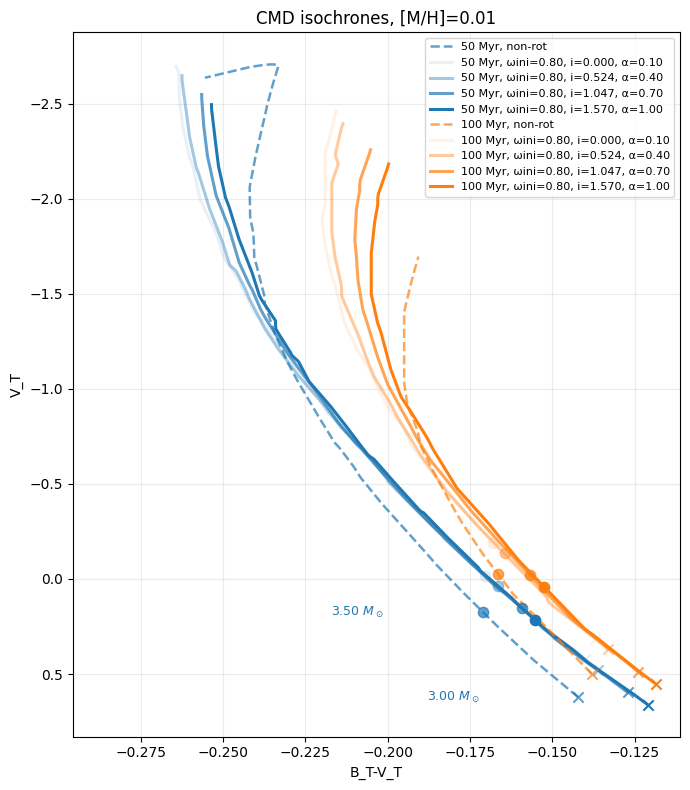

In [592]:
fig, ax = plot_cmd_isochrones(
    interp_func,
    Mini_grid=np.arange(3, 7.0 + 0.005, 0.005),
    # ages_Myr=(100, 150, 200),
    ages_Myr=(50, 100, ),
    MH=0.01,
    omega_ini_list=(0.0, 0.8),
    inclination_list=(0.0, 0.524, 1.047, 1.57),
    # color="G_BP-G_RP",
    # mag="G",
    color='B_T-V_T',
    mag='V_T',
    # color="J-Ks",
    # mag="H",
    rot_alpha_range=(0.1, 1.0),
    nonrot_alpha=0.7,
    mass_marks=(1.5, 2.0, 2.5, 3.0, 3.5),
    mass_marker_cycle=("s", "^", "v", "x", "o"),
    mass_text_iso_index=0,
    mass_text_dx=-0.03,
    mass_text_dy=0.0,
)

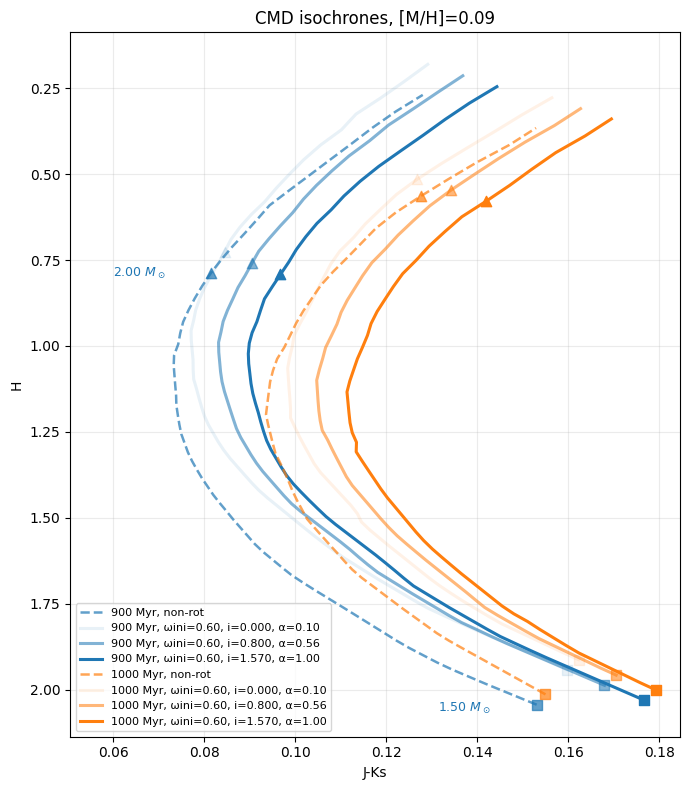

In [590]:
fig, ax = plot_cmd_isochrones(
    interp_func,
    Mini_grid=np.arange(1.5, 4.0 + 0.01, 0.01),
    ages_Myr=(900, 1000),
    # ages_Myr=(100, 200),
    MH=0.09,
    omega_ini_list=(0.0, 0.6),
    inclination_list=(0.0, 0.8, 1.57),
    # color="G_BP-G_RP",
    # mag="G",
    # color='B_T-V_T',
    # mag='V_T',
    color="J-Ks",
    mag="H",
    rot_alpha_range=(0.1, 1.0),
    nonrot_alpha=0.7,
    mass_marks=(1.5, 2.0, 2.5, 3.0, 3.5),
    mass_marker_cycle=("s", "^", "v", "x", "o"),
    mass_text_iso_index=0,
    mass_text_dx=-0.01,
    mass_text_dy=-0.01,
)

/Users/ziyinggu/Programming/GitHub/BELFAST/belfast/plot_utils.py:1202: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


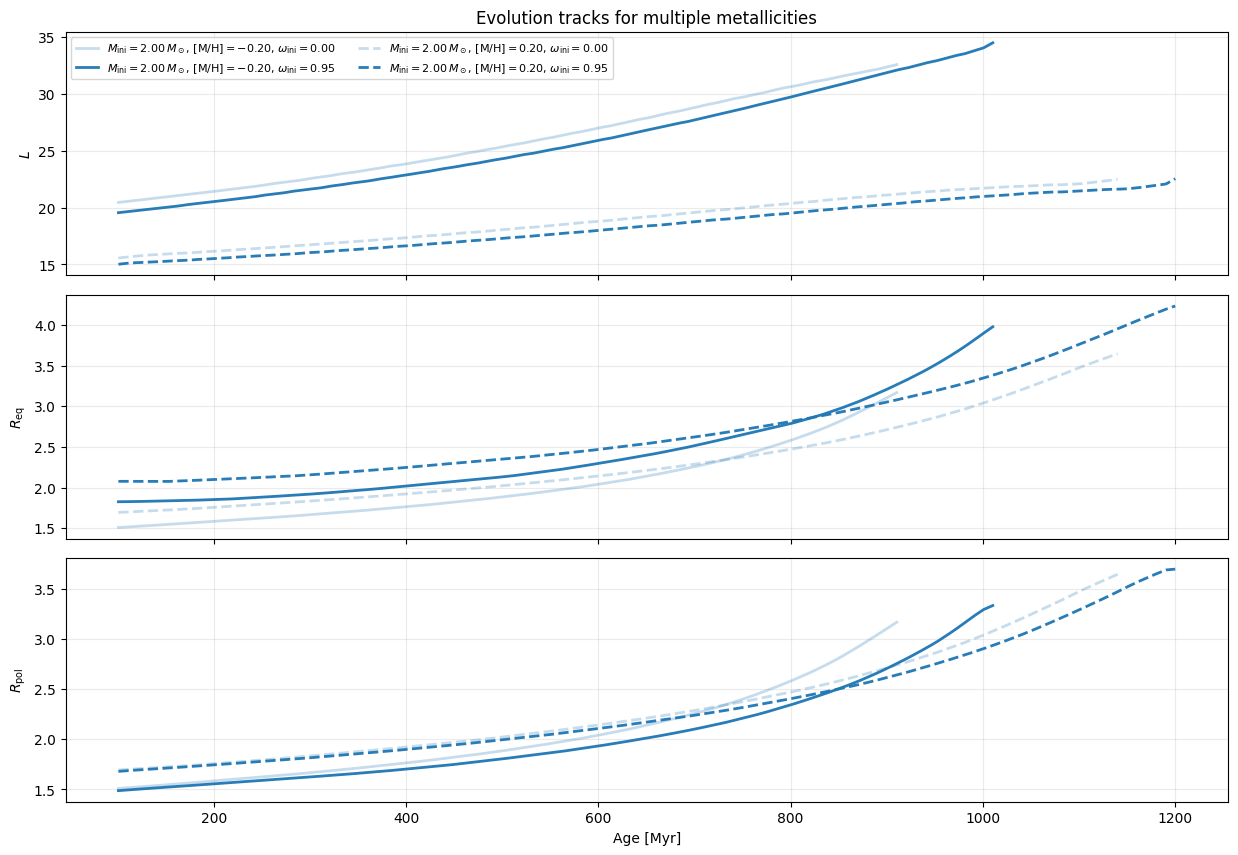

In [5]:
fig, axes = plot_evolution_L_R_tracks(
    interp_func=interp_func_pars,
    Mini_list=(2.0,),
    # age_Myr_grid=np.linspace(100, 5000, 901),
    age_Myr_grid=np.linspace(100, 2000, 5000),
    MH=[-0.2, 0.2],
    omega_ini_list=(0.0001, 0.95),
    omega_alpha_range=(0.25, 1.0),
    nonrot_alpha=0.5,
    figsize=(15, 10),
    # xlim=[800, 1200],
#     save_name='evolution of L, Req and Rpol (2 and 2.2.25 M_sun).pdf',
)

/var/folders/xc/rw1jkm1x0_1bhxz5h8s2_d200000gn/T/ipykernel_67311/1733909718.py:228: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


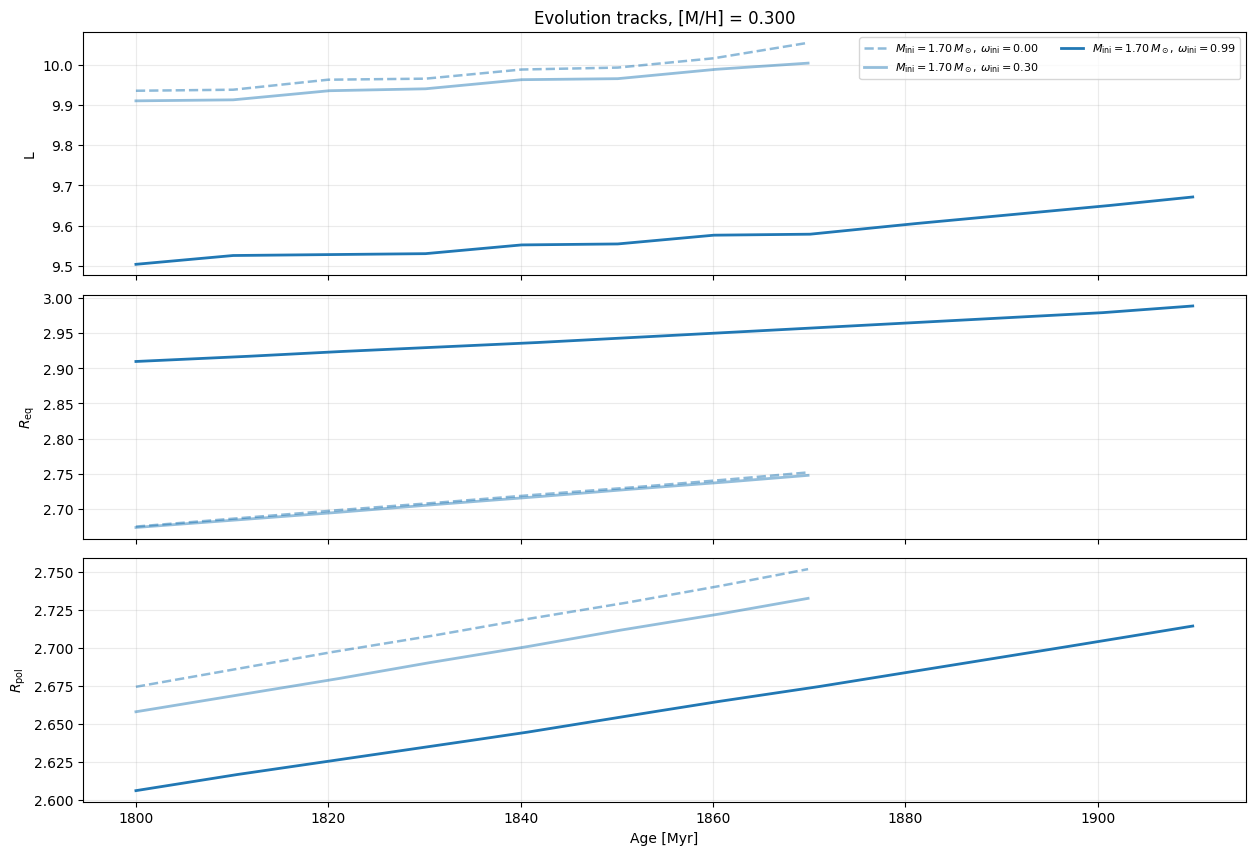

In [641]:
fig, axes = plot_evolution_L_R_tracks(
    interp_func=interp_func_pars,
    Mini_list=(1.7,),
    # age_Myr_grid=np.linspace(100, 5000, 901),
    age_Myr_grid=np.linspace(1800, 2000, 1901),
    MH=0.30,
    omega_ini_list=(0.0, 0.3, 0.99),
    omega_alpha_range=(0.25, 1.0),
    nonrot_alpha=0.5,
    figsize=(15, 10),
    # xlim=[800, 1200],
#     save_name='evolution of L, Req and Rpol (2 and 2.2.25 M_sun).pdf',
)